# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import r2_score, mean_squared_error

rng = np.random.default_rng(42)
pd.set_option('display.precision', 3)
RANDOM_STATE = 42
N_STORES = 400

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [2]:
N = N_STORES

# Predictors that actual effect revenue plus some randomness
floor_area = rng.lognormal(np.log(15), 0.6, N)                          # in thousands of sq ft; some very big stores
foot_traffic = 2.0 * floor_area ** 0.8 * np.exp(rng.normal(0, 0.25, N))  # bigger stores get more visits
median_income = rng.normal(65, 15, N)                                    # local median income, $ thousands
years_open = rng.uniform(1, 30, N)

# Linear combination of two factors: 0.6 x floor area + 0.4 x foot traffic, some randomness to
sales_capacity = 0.6 * floor_area + 0.4 * foot_traffic + rng.normal(0, 0.3, N)

stores = pd.DataFrame({"floor_area": floor_area, "foot_traffic": foot_traffic,
                       "median_income": median_income, "years_open": years_open,
                       "sales_capacity": sales_capacity})

# six irrelevant predictors
irrelevant = ["manager_tenure", "parking_spaces", "loyalty_signups",
              "delivery_radius", "staff_avg_age", "promo_emails"]
for name in irrelevant:
    stores[name] = rng.normal(0, 1, N)

# True revenue: $30k per thousand sq ft up to 25, only $12k per thousand sq ft above that
first_25 = np.where(floor_area < 25, floor_area, 25)           # floor area, capped at 25
above_25 = np.where(floor_area > 25, floor_area - 25, 0)       # the part above 25, or 0
true_mean = (30 * first_25 + 12 * above_25
             + 3 * foot_traffic + 2 * median_income + 3 * years_open)
# The noise is 5% of each store's own revenue, so bigger stores vary more
stores["revenue"] = true_mean + rng.normal(0, 1, N) * 0.05 * true_mean

features = [c for c in stores.columns if c != "revenue"]   # all 11 predictors
X = stores[features]
y = stores["revenue"]

print(f"{len(stores)} stores, {len(features)} predictors")
print(f"stores above 25k sq ft: {(stores['floor_area'] > 25).sum()}")
stores[["floor_area", "foot_traffic", "median_income", "years_open", "revenue"]].describe().round(1)

400 stores, 11 predictors
stores above 25k sq ft: 67


,floor_area,foot_traffic,median_income,years_open,revenue
count,400.0,400.0,400.0,400.0,400.0
mean,17.7,19.6,64.9,15.6,726.5
std,11.3,10.9,14.8,8.4,272.3
min,3.2,2.9,10.3,1.1,259.4
25%,10.1,12.3,56.0,8.3,520.9
50%,15.2,17.6,65.1,14.9,676.1
75%,21.4,24.0,74.2,23.5,876.2
max,86.2,73.3,112.7,30.0,1857.7


**Data-generating process**

400 stores, seed 42. Revenue (\$ thousands per month) is:

revenue = 30 × min(floor area, 25) + 12 × max(floor area − 25, 0) + 3 × foot traffic + 2 × median income + 3 × years open + noise

- **floor_area** (thousand sq ft): lognormal, median 15, with a long tail up to 86. Its effect bends at 25: \$30k per thousand sq ft below, \$12k above.
- **foot_traffic** (thousand visits a month): 2 × floor area^0.8, times random variation. Effect: \$3k per thousand visits.
- **median_income** (\$ thousands): normal, mean 65, sd 15. Effect: \$2k per \$1k of income.
- **years_open**: uniform from 1 to 30. Effect: \$3k per year.
- **sales_capacity**: 0.6 × floor area + 0.4 × foot traffic + a tiny bit of noise. It has **no effect of its own**; it's almost a linear combination of two real predictors.
- **Six irrelevant predictors** (manager_tenure, parking_spaces, loyalty_signups, delivery_radius, staff_avg_age, promo_emails): pure noise, **true effect zero**.
- **Noise:** normal, with a standard deviation of 5% of each store's true revenue, so the spread grows with store size. On average it's about \$39k, the error no model can remove.

### Step 1.2: Fit it the way they did (12 pts)

In [3]:
# Regression run with all the data
fit_all = sm.OLS(y, sm.add_constant(X)).fit()
print(f"Training R-squared, all 400 stores: {fit_all.rsquared:.4f}")

# The number the note left out: R-squared on stores the model never saw
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)
split_fit = LinearRegression().fit(X_tr, y_tr)

r2_train = r2_score(y_tr, split_fit.predict(X_tr))
r2_test = r2_score(y_te, split_fit.predict(X_te))
rmse_train = np.sqrt(mean_squared_error(y_tr, split_fit.predict(X_tr)))
rmse_test = np.sqrt(mean_squared_error(y_te, split_fit.predict(X_te)))
print(f"\nTraining stores (300): R-squared {r2_train:.4f}, RMSE ${rmse_train:.1f}k")
print(f"Held-out stores (100): R-squared {r2_test:.4f}, RMSE ${rmse_test:.1f}k")
print(f"Gap: {r2_train - r2_test:.4f} in R-squared, ${rmse_test - rmse_train:.1f}k in RMSE")

Training R-squared, all 400 stores: 0.9294

Training stores (300): R-squared 0.9300, RMSE $70.9k
Held-out stores (100): R-squared 0.9228, RMSE $77.4k
Gap: 0.0071 in R-squared, $6.5k in RMSE


Running a regression with every predictor on all 400 stores, OLS gives an R-squared of 0.9294, in the low 0.9s like the handover note. On 100 stores the model never saw, it drops to 0.9228, and the typical error rises from \$70.9k to \$77.4k a month: a gap of 0.0071 in R-squared and \$6.5k in RMSE. The gap is small, so overfitting isn't the main problem with this model. A high R-squared also hides how big the errors are: \$77k a month is about 11% of an average store's revenue.

### Step 1.3: Say what R-squared is (8 pts)

In [4]:
# Three columns of pure noise, from their own generator so the main draws stay the same
noise_rng = np.random.default_rng(7)
X_noise = X.copy()
for j in range(1, 4):
    X_noise[f"pure_noise_{j}"] = noise_rng.normal(0, 1, N)

fit_noise = sm.OLS(y, sm.add_constant(X_noise)).fit()
print(f"{'':<22}{'R-squared':>12}{'adjusted':>12}")
print(f"{'11 predictors':<22}{fit_all.rsquared:>12.6f}{fit_all.rsquared_adj:>12.6f}")
print(f"{'+ 3 noise columns':<22}{fit_noise.rsquared:>12.6f}{fit_noise.rsquared_adj:>12.6f}")

                         R-squared    adjusted
11 predictors             0.929432    0.927432
+ 3 noise columns         0.929941    0.927393


Adding three columns of pure noise raised R-squared from 0.929432 to 0.929941, even though none of them has anything to do with revenue. Adjusted R-squared, which penalizes each extra predictor, fell from 0.927432 to 0.927393. But adjusted R-squared is still measured on the same stores the model was fitted to, so it can't tell you how the model will do next month.

The Training R-squared can never go down when a predictor is added because OLS picks the coefficients that make the squared errors as small as possible, and the new predictor can always be given a coefficient of zero, which brings back the old fit exactly. So the fit can only stay the same or get incrementally better by fitting random patterns in the noise. So R-squared always favors larger models when you're comparing between them.



## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

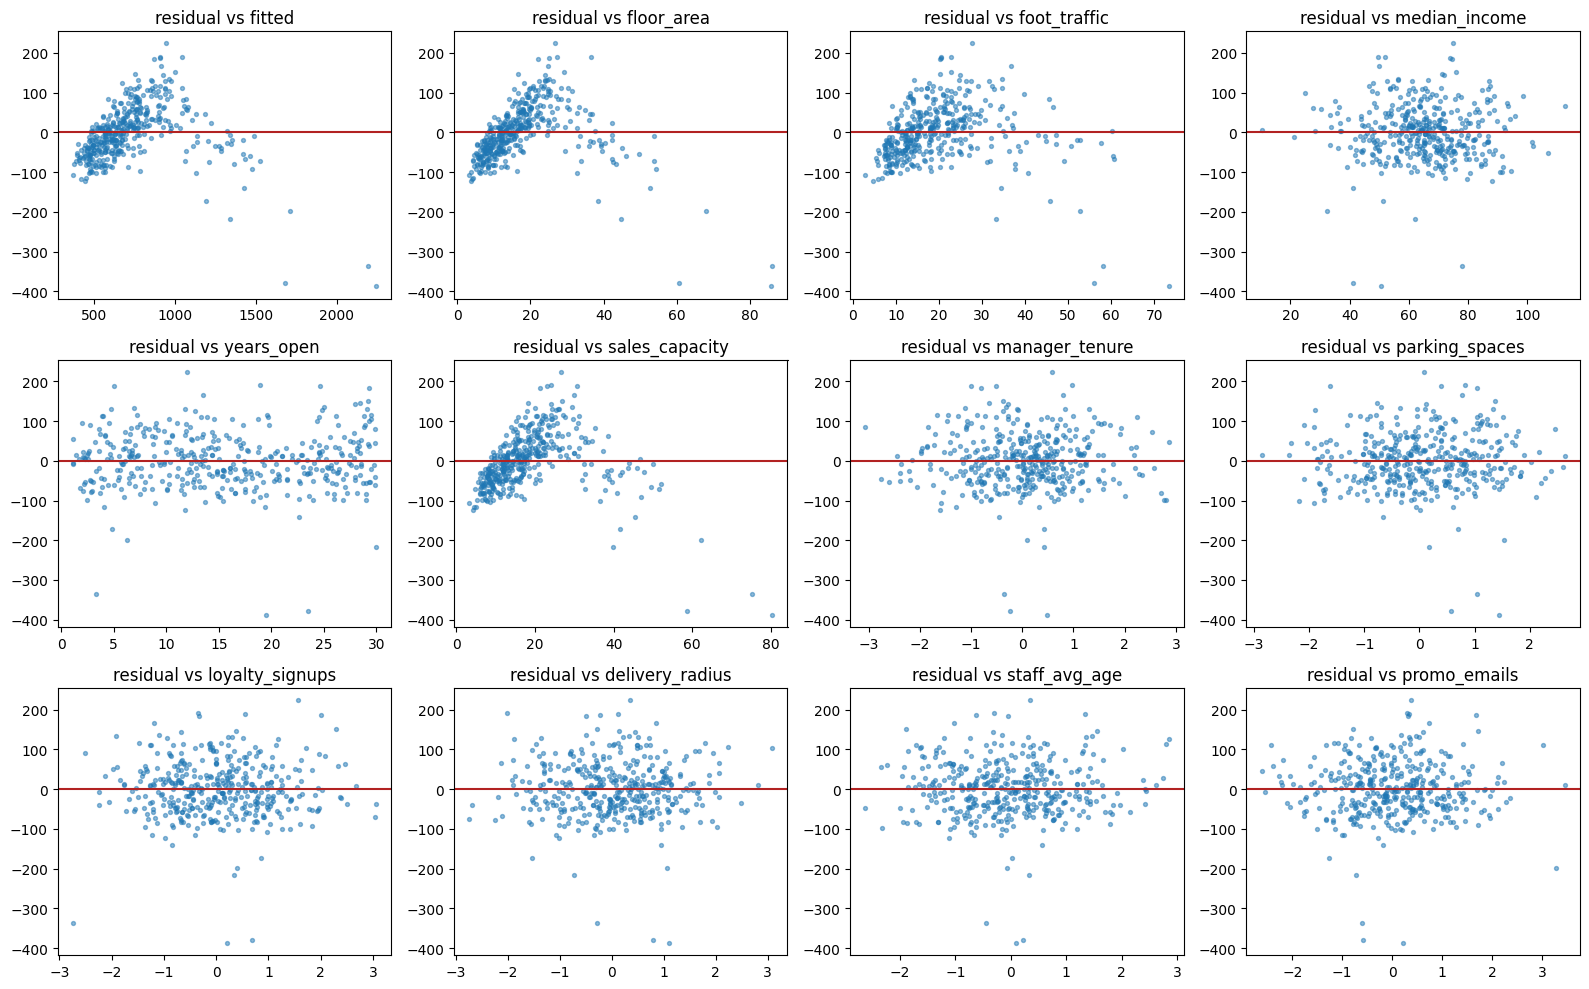

Breusch-Pagan p-value: 2.95e-20

 store   Cook D  leverage  floor area
   139    0.377     0.154        86.2
   248    0.292     0.101        85.7
   375    0.123     0.050        60.6
   226    0.086     0.111        67.9
   324    0.027     0.035        44.7

floor_area: coef 28.56, classical SE 7.483, HC3 SE 7.596
loyalty_signups: classical SE 3.707, HC3 SE 4.319


In [5]:
fitted = fit_all.fittedvalues
resid = fit_all.resid

# Residuals against fitted values, and against each of the 11 predictors
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()                       # 12 panels in one list
axes[0].scatter(fitted, resid, s=8, alpha=0.5)
axes[0].axhline(0, color="firebrick")
axes[0].set_title("residual vs fitted")
for ax, col in zip(axes[1:], features):
    ax.scatter(stores[col], resid, s=8, alpha=0.5)
    ax.axhline(0, color="firebrick")
    ax.set_title(f"residual vs {col}")
plt.tight_layout()
plt.show()

# Test for non-constant variance, and Cook's distance for influence
bp_p = het_breuschpagan(resid, fit_all.model.exog)[1]
infl = fit_all.get_influence()
cooks = infl.cooks_distance[0]
leverage = infl.hat_matrix_diag
print(f"Breusch-Pagan p-value: {bp_p:.2e}")
print(f"\n{'store':>6}{'Cook D':>9}{'leverage':>10}{'floor area':>12}")
for i in np.argsort(cooks)[::-1][:5]:
    print(f"{i:>6}{cooks[i]:>9.3f}{leverage[i]:>10.3f}{stores['floor_area'][i]:>12.1f}")

# What the non-constant variance does to the standard errors
fit_hc3 = sm.OLS(y, sm.add_constant(X)).fit(cov_type="HC3")
print(f"\nfloor_area: coef {fit_all.params['floor_area']:.2f}, classical SE {fit_all.bse['floor_area']:.3f}, "
      f"HC3 SE {fit_hc3.bse['floor_area']:.3f}")
print(f"loyalty_signups: classical SE {fit_all.bse['loyalty_signups']:.3f}, HC3 SE {fit_hc3.bse['loyalty_signups']:.3f}")

**1. Non-constant variance.** The residual-vs-fitted plot: small stores' residuals sit close to zero and big stores' spread far wider which results in a fan-out. Breusch-Pagan confirms non-constant variance (p ≈ 3e-20), which violates the constant-variance assumption. The estimate isn't biased by it. OLS still finds the right line on average. The standard error breaks because the classical formula assumes every store's error has the same spread. Robust standard errors are up to 17% larger than the classical ones (loyalty_signups: 3.707 classical against 4.319 robust), so classical intervals are too narrow for some coefficients.

**2. A non-linear relationship the model missed.** The residual-vs-floor-area points aren’t scattered evenly around zero. The residuals are negative for the smallest stores, positive in the middle, and negative for the biggest. That bend at 25k sq ft is something a straight line can't capture, which violates the assumption that the functional form is right. Unlike non-constant variance, it biases the estimate: no single slope is a correct estimate for both small and big stores, so the model is systematically wrong at both ends. It also makes the standard error misleading, because the missing curve gets counted as random noise.

**3. Influential observations.** The two biggest stores (139 and 248, about 86k sq ft each) have the largest Cook's distances, 0.38 and 0.29, more than twice the next one, because their floor area is so far from the rest (leverage 0.15 and 0.10). Neither store dominates the fit (neither Cook distance is above 1), but they pull the line toward themselves where the model is weakest. Influential points can move the estimate and the standard error, so they're worth checking.

### Step 2.2: The over-forecast on big stores (15 pts)

In [6]:
# Average error by store size decile
decile = pd.qcut(stores["floor_area"], 10, labels=False)     # 10 groups of 40 stores, smallest to biggest
by_size = pd.DataFrame({"decile": decile, "floor_area": stores["floor_area"],
                        "actual": y, "predicted": fitted}).groupby("decile").mean()
by_size["over_forecast"] = by_size["predicted"] - by_size["actual"]
by_size["over_pct"] = 100 * by_size["over_forecast"] / by_size["actual"]
print(by_size.round(1))

biggest = decile == 9
print(f"\nBiggest 10% of stores: over-forecast by ${by_size['over_forecast'][9]:.1f}k a month on average "
      f"({by_size['over_pct'][9]:.1f}%), and {(fitted[biggest] > y[biggest]).mean():.0%} of them are over-forecast")

# Variance inflation factors
Xv = sm.add_constant(X).values
print(f"\n{'predictor':<18}{'VIF':>8}")
for i, col in enumerate(features):
    print(f"{col:<18}{variance_inflation_factor(Xv, i + 1):>8.1f}")   # + 1 skips the constant in position 0

        floor_area  actual  predicted  over_forecast  over_pct
decile                                                        
0              5.7   383.4      452.4           69.0      18.0
1              8.1   452.6      498.4           45.8      10.1
2             10.1   525.3      556.4           31.2       5.9
3             12.1   580.0      599.6           19.6       3.4
4             13.9   640.0      635.6           -4.4      -0.7
5             16.3   711.0      689.8          -21.2      -3.0
6             18.4   791.7      746.7          -45.0      -5.7
7             21.5   882.7      815.1          -67.6      -7.7
8             26.7  1031.7      946.0          -85.7      -8.3
9             43.8  1266.9     1325.1           58.2       4.6

Biggest 10% of stores: over-forecast by $58.2k a month on average (4.6%), and 75% of them are over-forecast

predictor              VIF
floor_area           534.1
foot_traffic         232.7
median_income          1.0
years_open             1.0

Grouping stores into ten size bands, the model over-forecasts the biggest 10% (average 43.8k sq ft) by \$58.2k a month, 4.6% of their revenue, and 75% of those stores are over-forecast. It also over-forecasts the smallest stores (by \$69.0k, 18%) and under-forecasts the middle to large ones by up to \$86k. That pattern is because of the bend at 25k sq ft. Since revenue grows by a smaller amount above 25k sq ft, the model fits one straight slope, which is too flat for small stores and too steep for the biggest. So it predicts the biggest stores will earn more than they do. They carry the most revenue, so their errors cost the most in dollars.

**The collinear predictor.** Sales_capacity has a VIF of 1,353, and floor_area and foot_traffic have 534 and 233, because sales_capacity is almost exactly 0.6 × floor area + 0.4 × foot traffic. High VIF damages the predictors' coefficients and their standard errors. Since the regression can't differentiate the three predictors, it splits their effects arbitrarily. It gives sales_capacity a coefficient of −16.8, even though its true effect is zero, and the three standard errors are huge. This decision doesn't damage the predictions or the fit because the R-squared and the forecasts are unaffected, and dropping one wouldn't fix the over-forecast. Dropping sales_capacity solely due to a high VIF is incorrect. However, since it doesn't contribute anything meaningful to the data, dropping it would make the floor_area and foot_traffic coefficients easier to read, but the forecasting problem still won't be resolved.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

model                   terms  train RMSE  held-out RMSE
floor area only             1        86.2           92.5
4 core predictors           4        71.6           78.2
all 11                     11        70.9           77.4
all 11 + squares           22        44.6           59.3
+ all interactions         77        36.4           78.3
+ all cubic terms         363         0.0          278.5


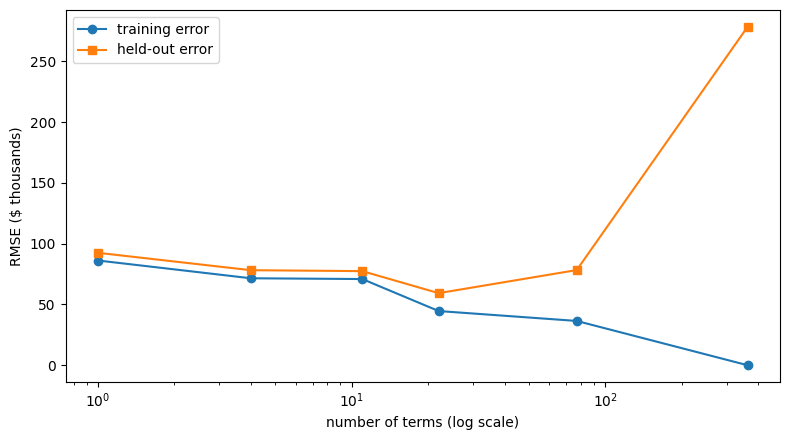

In [7]:
core = ["floor_area", "foot_traffic", "median_income", "years_open"]

def design(d, level):
    """The predictor table for the level of flexibility, 1 (simplest) to 6 (most flexible)."""
    if level == 1:
        return d[["floor_area"]]
    if level == 2:
        return d[core]
    if level == 3:
        return d[features]
    if level == 4:                                  # all 11, plus each one squared
        table = d[features].copy()
        for c in features:
            table[c + "^2"] = d[c] ** 2
        return table
    if level == 5:                                  # all squares and every pair multiplied together
        return PolynomialFeatures(degree=2, include_bias=False).fit_transform(d[features])
    return PolynomialFeatures(degree=3, include_bias=False).fit_transform(d[features])   # + every cubic term

labels = {1: "floor area only", 2: "4 core predictors", 3: "all 11",
          4: "all 11 + squares", 5: "+ all interactions", 6: "+ all cubic terms"}

n_terms, train_rmse, test_rmse = [], [], []
print(f"{'model':<22}{'terms':>7}{'train RMSE':>12}{'held-out RMSE':>15}")
for level in range(1, 7):
    m = LinearRegression().fit(design(X_tr, level), y_tr)
    n_terms.append(design(X_tr, level).shape[1])
    train_rmse.append(np.sqrt(mean_squared_error(y_tr, m.predict(design(X_tr, level)))))
    test_rmse.append(np.sqrt(mean_squared_error(y_te, m.predict(design(X_te, level)))))
    print(f"{labels[level]:<22}{n_terms[-1]:>7}{train_rmse[-1]:>12.1f}{test_rmse[-1]:>15.1f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(n_terms, train_rmse, "o-", label="training error")
ax.plot(n_terms, test_rmse, "s-", label="held-out error")
ax.set_xscale("log")
ax.set_xlabel("number of terms (log scale)")
ax.set_ylabel("RMSE ($ thousands)")
ax.legend()
plt.tight_layout()
plt.show()

Training error falls at every level, from \$86.2k to \$10.7k, as Step 1.3 predicts. Held-out error falls to its lowest at "all 11 + squares" (22 terms, \$59.3k), then rises to \$78.3k with interactions and \$207.2k with every cubic term, where the model has more terms (363) than training stores (300).

The left half (1 to 22 terms) is where bias dominates. The models are too simple to follow the bend in revenue, so they're wrong in a systematic way that more data wouldn't fix. Adding squared terms allows the model to curve, leading to the sharp drop in the held-out error at 22 terms. The right half is where the variance dominates. The extra terms start fitting noise in the 300 training stores, so the fit looks increasingly better on them and worse on new terms. The best held-out error, \$59.3k, is still above the \$39k because no model can have an error below about $39k and squares can only approximate the curve at 25k sq ft.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [8]:
folds = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(Xd, yd, level, kf):
    """The RMSE on each held-out fold, for one level of flexibility."""
    errs = []
    for tr, te in kf.split(Xd):
        m = LinearRegression().fit(design(Xd.iloc[tr], level), yd.iloc[tr])
        errs.append(np.sqrt(mean_squared_error(yd.iloc[te], m.predict(design(Xd.iloc[te], level)))))
    return np.array(errs)

# Choose by 5-fold CV on all 400 stores
levels = [1, 2, 3, 4, 5, 6]
cv_results = []                                   # each model's five fold errors, in order
print(f"{'model':<22}{'CV RMSE':>10}{'SE':>8}")
for level in levels:
    e = cv_rmse(X, y, level, folds)
    cv_results.append(e)
    print(f"{labels[level]:<22}{e.mean():>10.1f}{e.std(ddof=1) / np.sqrt(5):>8.2f}")

cv_means = [e.mean() for e in cv_results]
best = levels[np.argmin(cv_means)]                # the level with the smallest CV error
e = cv_results[np.argmin(cv_means)]
se = e.std(ddof=1) / np.sqrt(5)
print(f"\nCV chooses: {labels[best]}, CV RMSE ${e.mean():.1f}k, "
      f"95% interval [${e.mean() - 1.96 * se:.1f}k, ${e.mean() + 1.96 * se:.1f}k]")
print(f"fold RMSEs: {np.round(e, 1)}")

# Nested CV as a fix
outer = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
nested_scores, chosen = [], []
for out_tr, out_te in outer.split(X):
    X_in, y_in = X.iloc[out_tr], y.iloc[out_tr]
    inner = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    inner_means = [cv_rmse(X_in, y_in, level, inner).mean() for level in levels]
    pick = levels[np.argmin(inner_means)]
    chosen.append(pick)
    m = LinearRegression().fit(design(X_in, pick), y_in)
    nested_scores.append(np.sqrt(mean_squared_error(y.iloc[out_te], m.predict(design(X.iloc[out_te], pick)))))

nested_scores = np.array(nested_scores)
nse = nested_scores.std(ddof=1) / np.sqrt(5)
print(f"\nNested CV estimate: ${nested_scores.mean():.1f}k, "
      f"95% interval [${nested_scores.mean() - 1.96 * nse:.1f}k, ${nested_scores.mean() + 1.96 * nse:.1f}k]")
print(f"level chosen in each outer fold: {chosen}")

model                    CV RMSE      SE
floor area only             88.8    6.50
4 core predictors           73.9    6.68
all 11                      74.1    6.99
all 11 + squares            58.0   11.66
+ all interactions          70.3   14.09
+ all cubic terms          548.7  135.75

CV chooses: all 11 + squares, CV RMSE $58.0k, 95% interval [$35.2k, $80.9k]
fold RMSEs: [ 45.2 101.8  62.1  42.7  38.4]

Nested CV estimate: $58.0k, 95% interval [$35.2k, $80.9k]
level chosen in each outer fold: [4, 4, 4, 4, 4]


Five-fold cross-validation picks "all 11 + squares," with an expected error of about \$58.0k a month (95% interval \$35.2k to \$80.9k).

**The problem:** that \$58.0k was computed on the same folds used to choose the model. Picking the smallest of six CV errors tends to pick a model whose score was partly lucky, so the winning number is usually too optimistic. The fix is nested cross-validation, where an inner CV chooses the model using only each outer fold's training stores, and the outer fold, never used in the choice, gives the score. Nested CV gives the same \$58.0k (interval \$35.2k to \$80.9k), because the inner search chose "all 11 + squares" in all five outer folds, so there was no lucky pick to correct for. The number I'd report is the nested one because it's the expected error of the whole procedure, search included, on stores like these 400.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

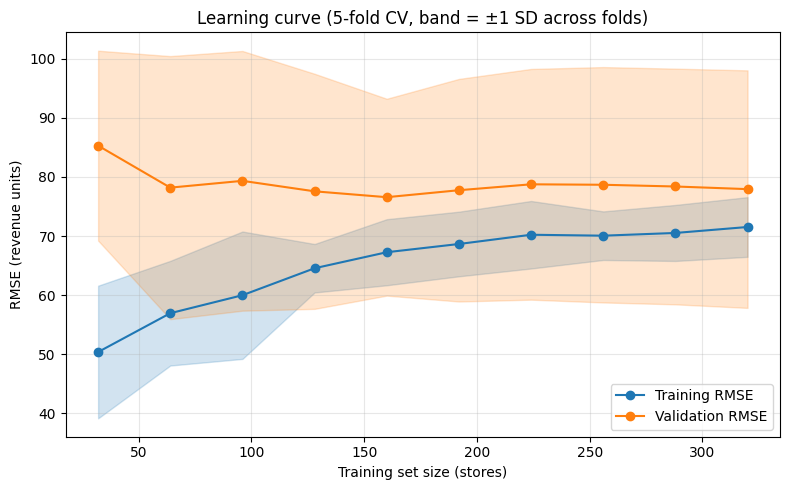

Final training RMSE:        71.53
Final validation RMSE:      77.94
Gap (val - train):          6.41 (8% of val error)
Val RMSE vs predict-mean:   29% (lower = more signal captured)
Val slope, last 3 sizes:    -1.5% per +100 stores

Diagnosis:
Reasonably well fit: small gap and low plateau. Remaining error is likely noise; gains from either investment will be modest.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ---------------------------------------------------------------
# X (400 x ~12) and y (store revenue) are assumed to already exist.
# Replace the model below with whatever you actually deploy: the
# diagnosis is about THAT model, not about the data in the abstract.
# ---------------------------------------------------------------
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

cv = KFold(n_splits=5, shuffle=True, random_state=0)
train_sizes_frac = np.linspace(0.1, 1.0, 10)

sizes, train_scores, val_scores = learning_curve(
    model, X, y,
    train_sizes=train_sizes_frac,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    shuffle=True,
    random_state=0,
)

# sklearn returns negative RMSE (higher is better); flip to plain RMSE.
train_err = -train_scores  # shape: (n_sizes, n_folds)
val_err = -val_scores
tr_mean, tr_std = train_err.mean(axis=1), train_err.std(axis=1)
va_mean, va_std = val_err.mean(axis=1), val_err.std(axis=1)

# ---------------------------------------------------------------
# Plot: both curves on one axis, shaded band = +/- 1 std across folds
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes, tr_mean, "o-", color="tab:blue", label="Training RMSE")
ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std,
                color="tab:blue", alpha=0.2)
ax.plot(sizes, va_mean, "o-", color="tab:orange", label="Validation RMSE")
ax.fill_between(sizes, va_mean - va_std, va_mean + va_std,
                color="tab:orange", alpha=0.2)
ax.set_xlabel("Training set size (stores)")
ax.set_ylabel("RMSE (revenue units)")
ax.set_title("Learning curve (5-fold CV, band = ±1 SD across folds)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# Interpretation
#
# GAP between the curves (validation - training) measures VARIANCE:
#   The model fits the stores it has seen better than stores it has
#   not. A big gap means it is memorizing noise specific to the
#   training sample (overfitting). Small training error + large
#   validation error = high variance.
#   -> More data helps: with more stores, noise averages out and the
#      curves move toward each other. Regularization or fewer/simpler
#      features also attack this.
#
# LEVEL both curves converge to measures BIAS (plus irreducible noise):
#   If training and validation error are close to each other but both
#   are high, the model cannot represent the revenue pattern even on
#   data it has seen. Underfitting. The plateau is the model-class
#   ceiling.
#   -> More data will NOT help: the validation curve is already flat,
#      so extra stores just reproduce the same plateau. You need
#      better features (interactions, nonlinearity, new signals such
#      as foot traffic, local demographics, competitor proximity) or a
#      more flexible model.
#
# Caveat: a high plateau can also be irreducible noise (revenue driven
# by things you do not measure). Tell bias from noise by checking
# whether a more flexible model (e.g. gradient boosting) or new
# features lower the plateau. If nothing does, you've hit the noise floor.
#
# The slope of the validation curve at the right edge is the key signal
# for "will more data help": still falling = yes, flat = no.
# ---------------------------------------------------------------
final_gap = va_mean[-1] - tr_mean[-1]
rel_gap = final_gap / va_mean[-1]

# Slope of validation error over the last 3 points, as % of its level
last = slice(-3, None)
slope = np.polyfit(sizes[last], va_mean[last], 1)[0]
pct_per_100_stores = 100 * slope * 100 / va_mean[-1]

baseline_rmse = np.std(y)  # RMSE of always predicting the mean
rel_to_baseline = va_mean[-1] / baseline_rmse

print(f"Final training RMSE:        {tr_mean[-1]:,.2f}")
print(f"Final validation RMSE:      {va_mean[-1]:,.2f}")
print(f"Gap (val - train):          {final_gap:,.2f} ({rel_gap:.0%} of val error)")
print(f"Val RMSE vs predict-mean:   {rel_to_baseline:.0%} (lower = more signal captured)")
print(f"Val slope, last 3 sizes:    {pct_per_100_stores:+.1f}% per +100 stores")

# Rule-of-thumb thresholds: adjust to your cost of error.
high_gap = rel_gap > 0.25
still_improving = pct_per_100_stores < -3
high_level = rel_to_baseline > 0.5

print("\nDiagnosis:")
if high_gap and still_improving:
    print("HIGH VARIANCE, still improving -> more stores should help; "
          "also consider regularization.")
elif high_gap:
    print("HIGH VARIANCE, curve flattening -> more stores give diminishing "
          "returns; simplify the model or regularize.")
elif high_level:
    print("HIGH BIAS -> curves are close but plateau high. More stores will "
          "not help; invest in features or a more flexible model.")
else:
    print("Reasonably well fit: small gap and low plateau. Remaining error "
          "is likely noise; gains from either investment will be modest.")

Claude's learning curve, for the plain linear model with all 11 predictors, ends with a training RMSE of \$71.5k and a validation RMSE of \$77.9k. Its code concludes the model is "reasonably well fit" and the remaining error is "likely noise," so neither more stores nor better features would make a difference.

The learning curve agrees with Phase 3 on the point that more stores won't help, but disagrees on what the remaining error is, and Phase 3 is right. The true noise level is about \$39k, half the \$78k plateau, and adding squared terms in Step 3.1 cut the held-out error to \$59k, which is the AI's own test for telling bias from noise. The model is missing the bend in revenue above 25k sq ft, so it's biased. The AI's code called it well fit because it compares the error with always predicting the average revenue, which any reasonable model beats. Beating a terrible guess doesn't mean you're close to the best possible model.

**More stores or better features?** The best choice is better features. More stores would barely help, because the validation curve is already flat, but adding squared terms, a better set of features for the same 400 stores, cut the held-out error from \$77k to about \$58k in phase 3.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [13]:
# 300 columns of pure noise
X_stores = X.copy()                                   # keeping the real predictors
X = np.random.default_rng(2026).normal(0, 1, (400, 300))
print(f"X is now {X.shape[0]} stores x {X.shape[1]} noise columns; y is still Phase 1's revenue")

X is now 400 stores x 300 noise columns; y is still Phase 1's revenue


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.10


In [15]:
from sklearn.pipeline import make_pipeline

# The same three steps inside a pipeline, so they're redone inside each fold
honest_pipe = make_pipeline(StandardScaler(), SelectKBest(f_regression, k=20), LinearRegression())
honest = cross_val_score(honest_pipe, X, y, cv=5, scoring="r2")

# The analyst's version, but without the scaler
X_sel_no_scale = SelectKBest(f_regression, k=20).fit_transform(X, y)
no_scale = cross_val_score(LinearRegression(), X_sel_no_scale, y, cv=5, scoring="r2")

print(f"Analyst's cell (steps fitted on all the data): R^2 = {scores.mean():.4f}")
print(f"Inside a Pipeline (steps refitted per fold):   R^2 = {honest.mean():.4f}")
print(f"Gap:                                           {scores.mean() - honest.mean():.4f}")
print(f"Analyst's cell without the scaler:             R^2 = {no_scale.mean():.4f}")

Analyst's cell (steps fitted on all the data): R^2 = 0.0994
Inside a Pipeline (steps refitted per fold):   R^2 = -0.2044
Gap:                                           0.3038
Analyst's cell without the scaler:             R^2 = 0.0994



**(a)** The step that makes the score look too good is SelectKBest. It picks the 20 columns that best match revenue, but it looks at all 400 stores to do it, including the stores that cross-validation later uses as test stores. With 300 random columns, a few will match revenue just by luck, and SelectKBest picks exactly those. The test stores helped choose the columns they're tested on. StandardScaler is harmless because it only rescales the predictors and never looks at revenue. And for a regression with an intercept, rescaling a predictor doesn't change the predictions at all. Running the analyst's cell without the scaler gives exactly the same score, 0.0994.

**(b)** I gave the analyst's cell 300 columns of pure random noise, none of which has anything to do with revenue. It still printed a "validated" R-squared of 0.0994. When I ran the same three steps inside a Pipeline, so the column choice is redone inside each fold without seeing the test stores, the score was −0.2044. That's worse than just guessing the average revenue, which is the honest answer for columns that predict nothing. The gap is 0.30, meaning the analyst's method made pure noise look like a working model.

**(c)** It's a special case of the Step 3.2 problem: in both, the stores used to test the model also helped choose it, so the score comes out too good.

### Task 4.3: The handover note (3 pts)

The model predicts each store's monthly revenue (in \$ thousands) from its floor area, foot traffic, local median income and years open. The other seven predictors don't help: six have no effect at all, and sales_capacity just repeats floor area and foot traffic.

With stores it has never seen, the model is off by about \$58k a month per store (95% interval: \$35k to \$81k). I measured this only on stores the model had never seen, so it reflects how the model will really do next month. The old "R-squared 0.94, validated" was measured on the same stores the model learned from, so it isn't relevant for future months.

The model fails in two situations. First, with very big stores(above about 25k sq ft), each extra square foot adds less revenue. The old straight-line model guessed too high for the biggest 10% of stores, by about \$58k a month. The new model's squared terms shrink that error but don't remove it, and for stores bigger than any in our data (over 86k sq ft), its predictions are guesses. Second, the model only knows how these 400 stores behaved in the past. If the market shifts or new kinds of stores open, its errors will grow, and its accuracy number won't warn us.

Next, I'd build a model that captures the slowdown above 25k sq ft directly, and compare its forecasts with actual revenue every month, so problems can be found earlier.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

Model and date: Sonnet 5.5 medium, 11/18/26

Prompt:

```text
[Prep] Act as a machine learning engineer who diagnoses model
performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and
about 12 predictors. Write Python that produces a learning curve --
training and validation error as a function of training set size --
and interprets it to distinguish a high-bias problem from a
high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot
both curves on one axis with a shaded band for variability across
folds.

[Mechanism Check] Add comments explaining what the GAP between the two
curves indicates versus what the LEVEL both converge to indicates, and
what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better
features is the higher-return investment.
```

Reply:

I'll write the script and check that it runs. Your X and y didn't come through, so I'll test on synthetic data.

I can't tell you whether more stores or better features is the better investment, because your X and y didn't come through and I have no data to run on. I did test `learning_curve_diagnosis.py` on synthetic data shaped like yours (400 rows, 12 predictors), and it runs end to end. It saves `learning_curve.png` and prints a diagnosis.

**What the script does**
- It fits a Ridge regression on standardized features and computes RMSE at 10 training sizes with 5-fold CV. The model is a placeholder, so swap in whatever you actually deploy.
- It plots training and validation RMSE on one axis, with a ±1 SD band across folds.
- The comments explain how to read the curves, and the script prints a verdict based on three numbers:
  - the final gap between the curves
  - the slope of the validation curve at the right edge
  - validation error relative to a predict-the-mean baseline

**How to read your result**

| What you see | Diagnosis | Higher-return investment |
|---|---|---|
| Large gap, validation curve still falling | High variance | More stores, or regularization |
| Large gap, validation curve flat | High variance, diminishing returns | Simpler model or regularization, not more data |
| Small gap, both plateau high | High bias | Better features or a more flexible model |
| Small gap, low plateau | Well fit | Little to gain from either |

- **Gap:** this measures variance. More data shrinks it.
- **Level:** this measures bias plus irreducible noise. More data doesn't lower a plateau.
- **Slope:** the slope of the validation curve over the last few points is the best single indicator of whether more stores would help.

In my synthetic test the curves nearly touched, with a 4% gap, and sat at a high plateau. The script correctly flagged high bias and recommended features over more data.

A high plateau can also be noise you can't measure. To check, try a gradient-boosting model or a few candidate features, and see whether the plateau drops. If it doesn't, you've likely hit the noise floor.

With only 400 stores and 5 folds, the largest training size is 320, so you only see the curve out to about 80% of your data. A still-falling validation curve at that point is a reasonable sign more stores would help, but it is an extrapolation.

If you paste the printed output, or upload X and y as a CSV, I'll interpret the actual curve and give you a real recommendation.

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# ---------------------------------------------------------------
# X (400 x ~12) and y (store revenue) are assumed to already exist.
# Replace the model below with whatever you actually deploy: the
# diagnosis is about THAT model, not about the data in the abstract.
# ---------------------------------------------------------------
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))

cv = KFold(n_splits=5, shuffle=True, random_state=0)
train_sizes_frac = np.linspace(0.1, 1.0, 10)

sizes, train_scores, val_scores = learning_curve(
    model, X, y,
    train_sizes=train_sizes_frac,
    cv=cv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    shuffle=True,
    random_state=0,
)

# sklearn returns negative RMSE (higher is better); flip to plain RMSE.
train_err = -train_scores  # shape: (n_sizes, n_folds)
val_err = -val_scores
tr_mean, tr_std = train_err.mean(axis=1), train_err.std(axis=1)
va_mean, va_std = val_err.mean(axis=1), val_err.std(axis=1)

# ---------------------------------------------------------------
# Plot: both curves on one axis, shaded band = +/- 1 std across folds
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sizes, tr_mean, "o-", color="tab:blue", label="Training RMSE")
ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std,
                color="tab:blue", alpha=0.2)
ax.plot(sizes, va_mean, "o-", color="tab:orange", label="Validation RMSE")
ax.fill_between(sizes, va_mean - va_std, va_mean + va_std,
                color="tab:orange", alpha=0.2)
ax.set_xlabel("Training set size (stores)")
ax.set_ylabel("RMSE (revenue units)")
ax.set_title("Learning curve (5-fold CV, band = ±1 SD across folds)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# Interpretation
#
# GAP between the curves (validation - training) measures VARIANCE:
#   The model fits the stores it has seen better than stores it has
#   not. A big gap means it is memorizing noise specific to the
#   training sample (overfitting). Small training error + large
#   validation error = high variance.
#   -> More data helps: with more stores, noise averages out and the
#      curves move toward each other. Regularization or fewer/simpler
#      features also attack this.
#
# LEVEL both curves converge to measures BIAS (plus irreducible noise):
#   If training and validation error are close to each other but both
#   are high, the model cannot represent the revenue pattern even on
#   data it has seen. Underfitting. The plateau is the model-class
#   ceiling.
#   -> More data will NOT help: the validation curve is already flat,
#      so extra stores just reproduce the same plateau. You need
#      better features (interactions, nonlinearity, new signals such
#      as foot traffic, local demographics, competitor proximity) or a
#      more flexible model.
#
# Caveat: a high plateau can also be irreducible noise (revenue driven
# by things you do not measure). Tell bias from noise by checking
# whether a more flexible model (e.g. gradient boosting) or new
# features lower the plateau. If nothing does, you've hit the noise floor.
#
# The slope of the validation curve at the right edge is the key signal
# for "will more data help": still falling = yes, flat = no.
# ---------------------------------------------------------------
final_gap = va_mean[-1] - tr_mean[-1]
rel_gap = final_gap / va_mean[-1]

# Slope of validation error over the last 3 points, as % of its level
last = slice(-3, None)
slope = np.polyfit(sizes[last], va_mean[last], 1)[0]
pct_per_100_stores = 100 * slope * 100 / va_mean[-1]

baseline_rmse = np.std(y)  # RMSE of always predicting the mean
rel_to_baseline = va_mean[-1] / baseline_rmse

print(f"Final training RMSE:        {tr_mean[-1]:,.2f}")
print(f"Final validation RMSE:      {va_mean[-1]:,.2f}")
print(f"Gap (val - train):          {final_gap:,.2f} ({rel_gap:.0%} of val error)")
print(f"Val RMSE vs predict-mean:   {rel_to_baseline:.0%} (lower = more signal captured)")
print(f"Val slope, last 3 sizes:    {pct_per_100_stores:+.1f}% per +100 stores")

# Rule-of-thumb thresholds: adjust to your cost of error.
high_gap = rel_gap > 0.25
still_improving = pct_per_100_stores < -3
high_level = rel_to_baseline > 0.5

print("\nDiagnosis:")
if high_gap and still_improving:
    print("HIGH VARIANCE, still improving -> more stores should help; "
          "also consider regularization.")
elif high_gap:
    print("HIGH VARIANCE, curve flattening -> more stores give diminishing "
          "returns; simplify the model or regularize.")
elif high_level:
    print("HIGH BIAS -> curves are close but plateau high. More stores will "
          "not help; invest in features or a more flexible model.")
else:
    print("Reasonably well fit: small gap and low plateau. Remaining error "
          "is likely noise; gains from either investment will be modest.")
```

Changes I made:
- The AI couldn't access my X and y, so it only tested its code on made-up data. I ran its code, unchanged, in my own notebook on my store data. The numbers and conclusions in my Task 4.1 answer come from that run.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.